# Real Field Benchmark: Equinor Volve Production Data

## Supervisor-facing purpose
This notebook adds a genuine field-data experiment to the project. It loads Equinor’s released daily production workbook, filters the six producing wellbores, aggregates measured observations to calendar-month summaries, engineers lagged history features, and evaluates future oil-rate and downhole-pressure prediction.

**Scope warning:** Volve was produced with water injection for field pressure support. Its production workbook does not identify whether each producer was naturally flowing or artificially lifted, and it does not provide a confirmed natural-flow transition date. Accordingly, this notebook evaluates field production/pressure forecasting only. It does **not** train or score natural-flow-inadequacy labels and does not validate solution-gas-drive transition predictions.

## License and sources
The original workbook is included under Equinor’s Volve terms, which require attribution and a link to the terms and prohibit sale. See `docs/volve_data_and_license.md`. Dataset source: [Equinor Volve data sharing](https://www.equinor.com/energy/volve-data-sharing). Field-context source: [Norwegian Offshore Directorate: Volve](https://www.norskpetroleum.no/en/facts/field/volve/).

## Running cell by cell
Run the cells top to bottom. The workbook is stored at `data/raw/volve/Volve production data.xlsx`. The displayed forecast metrics use real Volve field observations, but only six producing wellbores from one water-injection-supported field are available in this subset. They must not be generalized as performance on solution-gas-drive wells or other fields.

## 1. Imports and project paths
The baseline is a tabular gradient-boosting regressor. A persistence forecast is included as a simple reference. The target is a future monthly mean based on observed daily rows. Pressure is the source’s `AVG_DOWNHOLE_PRESSURE`, preserved as dynamic/downhole pressure rather than being mislabeled as static reservoir pressure.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from sgd_ml.volve import load_volve_daily, aggregate_volve_monthly, add_monthly_forecast_targets
from sgd_ml.features import engineer_history
from sgd_ml.modeling import make_regressor, evaluate_regression

## 2. Loading source field observations
The source daily sheet distinguishes producing (`OP`) and injection (`WI`) wellbore rows. The loader retains producer rows only. It does not infer lift status from producer status.

In [2]:
SOURCE_PATH = ROOT / "data/raw/volve/Volve production data.xlsx"
daily = load_volve_daily(SOURCE_PATH)
profile = pd.DataFrame({"rows": [len(daily)], "producing_wells": [daily.well_id.nunique()], "first_date": [daily.date.min().date()], "last_date": [daily.date.max().date()], "lift_status_known": [False]})
display(profile)
display(daily.groupby("well_id").agg(first_date=("date", "min"), last_date=("date", "max"), daily_records=("date", "size"), oil_observed=("oil_rate", "count"), downhole_pressure_observed=("bhp", "count")))

,rows,producing_wells,first_date,last_date,lift_status_known
0,9143,6,2008-02-12,2016-09-17,False


,first_date,last_date,daily_records,oil_observed,downhole_pressure_observed
well_id,,,,,
15/9-F-1 C,2014-04-08,2016-04-21,744,744,740
15/9-F-11,2013-07-08,2016-09-17,1165,1165,1144
15/9-F-12,2008-02-12,2016-09-17,3056,3056,955
15/9-F-14,2008-02-12,2016-09-17,3056,3056,2850
15/9-F-15 D,2014-01-12,2016-09-17,978,978,978
15/9-F-5,2016-04-12,2016-09-17,144,144,0


## 3. Missingness and source-unit review
Missing pressure readings are substantial for some wellbores. The source workbook uses abbreviated field codes; the project preserves the original columns and avoids silently converting units. Confirm the source data dictionary before combining Volve with other datasets or interpreting metric magnitudes as standardized engineering units.

In [3]:
coverage = pd.DataFrame({"missing_count": daily.isna().sum(), "missing_fraction": daily.isna().mean()})
display(coverage.sort_values("missing_fraction", ascending=False))
print("Source pressure column is AVG_DOWNHOLE_PRESSURE -> project field bhp; not static reservoir pressure.")
print("Lift status is unknown in this workbook; no natural-flow transition labels are available.")

,missing_count,missing_fraction
BORE_WI_VOL,9143,1.000000
downhole_temperature,2476,0.270808
bhp,2476,0.270808
annulus_pressure,2472,0.270371
tubing_pressure,352,0.038499
wellhead_temperature,315,0.034453
wellhead_pressure,283,0.030953
choke,242,0.026468
choke_pressure_drop,6,0.000656
NPD_WELL_BORE_CODE,0,0.000000


Source pressure column is AVG_DOWNHOLE_PRESSURE -> project field bhp; not static reservoir pressure.
Lift status is unknown in this workbook; no natural-flow transition labels are available.


## 4. Monthly aggregation and forecast labels
Daily values are averaged within each calendar month per well; observed shut-in zero-production days remain part of the average. Empty months remain missing and are not filled with interpolated production or pressure. Future labels are joined by actual calendar month at +1 and +3 months rather than assuming each row is exactly one month apart.

In [4]:
monthly = aggregate_volve_monthly(daily)
monthly = add_monthly_forecast_targets(monthly, horizons=(1, 3))
print("Monthly panel shape:", monthly.shape)
display(monthly.groupby("well_id").agg(months=("date", "size"), oil_target_rows=("oil_rate_future_1m", "count"), pressure_rows=("bhp", "count")))

Monthly panel shape: (311, 21)


,months,oil_target_rows,pressure_rows
well_id,,,
15/9-F-1 C,25,24,25
15/9-F-11,39,38,39
15/9-F-12,104,103,33
15/9-F-14,104,103,100
15/9-F-15 D,33,32,33
15/9-F-5,6,5,0


## 5. Feature engineering using only history available at each forecast origin
The first feature set captures current production/pressure and lagged or trailing production behavior. This field subset has no verified reservoir-drive category, bubble-point pressure, PVT, or lift-status history. The feature set therefore does not pretend those variables are known.

In [5]:
featured = engineer_history(monthly, windows=(3, 6, 12))
HORIZON = 1
oil_target = f"oil_rate_future_{HORIZON}m"
pressure_target = f"bhp_future_{HORIZON}m"
excluded = {"well_id", "date", "oil_rate_future_1m", "oil_rate_future_3m", "bhp_future_1m", "bhp_future_3m", "lift_status", "development_context", "field", "flow_kind", "well_type"}
feature_cols = [c for c in featured.select_dtypes(include=["number", "object", "category", "bool"]).columns if c not in excluded and not c.startswith(("oil_rate_future", "bhp_future", "months_to_inadequate"))]
print("Predictors:", feature_cols)
display(featured[feature_cols + [oil_target, pressure_target]].head())

Predictors: ['oil_rate', 'gas_rate', 'water_rate', 'bhp', 'downhole_temperature', 'tubing_pressure', 'annulus_pressure', 'choke', 'on_stream_hours', 'wellhead_pressure', 'wellhead_temperature', 'choke_pressure_drop', 'region', 'elapsed_days', 'elapsed_months', 'calendar_year', 'calendar_month', 'oil_rate_lag1', 'oil_rate_mean3', 'oil_rate_mean6', 'oil_rate_mean12', 'oil_rate_slope3', 'gas_rate_lag1', 'gas_rate_mean3', 'gas_rate_mean6', 'gas_rate_mean12', 'gas_rate_slope3', 'water_rate_lag1', 'water_rate_mean3', 'water_rate_mean6', 'water_rate_mean12', 'water_rate_slope3', 'bhp_lag1', 'bhp_mean3', 'bhp_mean6', 'bhp_mean12', 'bhp_slope3', 'choke_lag1', 'choke_mean3', 'choke_mean6', 'choke_mean12', 'choke_slope3', 'downhole_temperature_lag1', 'downhole_temperature_mean3', 'downhole_temperature_mean6', 'downhole_temperature_mean12', 'downhole_temperature_slope3', 'tubing_pressure_lag1', 'tubing_pressure_mean3', 'tubing_pressure_mean6', 'tubing_pressure_mean12', 'tubing_pressure_slope3', 'a

/tmp/ipykernel_8591/1430817526.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  feature_cols = [c for c in featured.select_dtypes(include=["number", "object", "category", "bool"]).columns if c not in excluded and not c.startswith(("oil_rate_future", "bhp_future", "months_to_inadequate"))]


,oil_rate,gas_rate,water_rate,bhp,downhole_temperature,tubing_pressure,annulus_pressure,choke,on_stream_hours,wellhead_pressure,...,wellhead_temperature_mean6,wellhead_temperature_mean12,wellhead_temperature_slope3,choke_pressure_drop_lag1,choke_pressure_drop_mean3,choke_pressure_drop_mean6,choke_pressure_drop_mean12,choke_pressure_drop_slope3,oil_rate_future_1m,bhp_future_1m
0,484.455217,69475.506522,0.000000,281.283718,102.058556,224.593000,NaN,23.467264,9.891304,56.690718,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,803.288710,223.970505
1,803.288710,112781.601613,25.273548,223.970505,107.815733,155.976085,NaN,46.416057,23.672043,67.994420,...,33.315305,33.315305,NaN,35.803136,35.803136,35.803136,35.803136,NaN,653.925333,217.458386
2,653.925333,96222.056333,68.949333,217.458386,108.004911,157.561726,NaN,46.621148,23.530555,59.896660,...,44.446564,44.446564,NaN,39.485179,37.644157,37.644157,37.644157,NaN,485.456000,215.313723
3,485.456000,72383.966333,202.983667,215.313723,108.151182,166.593740,NaN,47.284669,23.947222,48.719983,...,48.408281,48.408281,11.508204,31.588820,35.625711,35.625711,35.625711,-2.107158,224.852581,230.621998
4,224.852581,33812.606452,146.120968,230.621998,105.879476,188.180684,NaN,29.241656,13.967473,42.441315,...,50.506781,50.506781,0.612229,20.253619,30.442539,31.782688,31.782688,-9.615780,305.614333,229.76302


## 6. Held-out-well evaluation: testing transfer to unseen wellbores
Complete wells are held out from fitting. This is the more relevant split for new-well generalization, but the test still comes from the same Volve field and development context. Use no well identifier as a predictor. The split uses five wells for training and one for testing by default; repeat group splits for uncertainty before any conclusion.

In [6]:
def grouped_fit_evaluate(data, target_name, seed=42):
    eligible = data.dropna(subset=[target_name]).copy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=1/6, random_state=seed)
    train_idx, test_idx = next(splitter.split(eligible, groups=eligible.well_id))
    train, test = eligible.iloc[train_idx], eligible.iloc[test_idx]
    model = make_regressor(train[feature_cols])
    model.fit(train[feature_cols], train[target_name])
    prediction = model.predict(test[feature_cols])
    persistence_target = "oil_rate" if target_name.startswith("oil_rate") else "bhp"
    valid = test[persistence_target].notna()
    persistence_prediction = test.loc[valid, persistence_target].to_numpy()
    observed = test[target_name].to_numpy()
    metrics = evaluate_regression(observed, prediction)
    metrics.update({"baseline_persistence_MAE": float(mean_absolute_error(observed[valid], persistence_prediction)), "train_wells": int(train.well_id.nunique()), "test_wells": int(test.well_id.nunique()), "test_rows": int(len(test)), "held_out_well_ids": ", ".join(sorted(test.well_id.unique()))})
    result = test[["well_id", "date", persistence_target, target_name]].copy()
    result["prediction"] = prediction
    result["absolute_error"] = np.abs(result[target_name] - result.prediction)
    return model, pd.DataFrame([metrics]), result

oil_model, oil_group_metrics, oil_group_predictions = grouped_fit_evaluate(featured, oil_target)
pressure_data = featured.dropna(subset=[pressure_target]).copy()
pressure_model, pressure_group_metrics, pressure_group_predictions = grouped_fit_evaluate(pressure_data, pressure_target)
print("Future oil-rate forecast on held-out well:")
display(oil_group_metrics)
print("Future downhole-pressure forecast on held-out well:")
display(pressure_group_metrics)

Future oil-rate forecast on held-out well:


,MAE,RMSE,R2,baseline_persistence_MAE,train_wells,test_wells,test_rows,held_out_well_ids
0,293.666519,336.573593,-2.246097,104.346315,5,1,24,15/9-F-1 C


Future downhole-pressure forecast on held-out well:


,MAE,RMSE,R2,baseline_persistence_MAE,train_wells,test_wells,test_rows,held_out_well_ids
0,18.205642,22.980327,-0.777616,12.293247,4,1,38,15/9-F-11


## 7. Purged chronological evaluation: forecasting future periods for known wells
This evaluation uses early dates for training and later dates for testing. Training rows whose target month would overlap the test period are purged to prevent label leakage across the cutoff. Each well can appear in both partitions, matching the use case of forecasting later periods for existing wells.

In [7]:
def chronological_fit_evaluate(data, target_name, horizon_months=1):
    eligible = data.dropna(subset=[target_name]).copy()
    cutoff = eligible.date.quantile(0.8)
    train = eligible.loc[eligible.date < cutoff - pd.DateOffset(months=horizon_months)].copy()
    test = eligible.loc[eligible.date >= cutoff].copy()
    model = make_regressor(train[feature_cols])
    model.fit(train[feature_cols], train[target_name])
    prediction = model.predict(test[feature_cols])
    observed = test[target_name].to_numpy()
    metrics = evaluate_regression(observed, prediction)
    source_target = "oil_rate" if target_name.startswith("oil_rate") else "bhp"
    metrics.update({"baseline_persistence_MAE": float(mean_absolute_error(observed, test[source_target])), "cutoff": str(cutoff.date()), "train_rows": len(train), "test_rows": len(test), "train_wells": int(train.well_id.nunique()), "test_wells": int(test.well_id.nunique())})
    result = test[["well_id", "date", source_target, target_name]].copy()
    result["prediction"] = prediction
    result["absolute_error"] = np.abs(result[target_name] - result.prediction)
    return model, pd.DataFrame([metrics]), result

oil_time_model, oil_time_metrics, oil_time_predictions = chronological_fit_evaluate(featured, oil_target, HORIZON)
pressure_time_model, pressure_time_metrics, pressure_time_predictions = chronological_fit_evaluate(pressure_data, pressure_target, HORIZON)
print("Purged future-time oil-rate validation:")
display(oil_time_metrics)
print("Purged future-time downhole-pressure validation:")
display(pressure_time_metrics)

Purged future-time oil-rate validation:


,MAE,RMSE,R2,baseline_persistence_MAE,cutoff,train_rows,test_rows,train_wells,test_wells
0,140.266453,176.974081,0.627212,52.986891,2015-08-01,235,65,5,6


Purged future-time downhole-pressure validation:


,MAE,RMSE,R2,baseline_persistence_MAE,cutoff,train_rows,test_rows,train_wells,test_wells
0,19.56491,32.013257,0.073175,13.519417,2015-08-01,176,46,5,4


## 8. Field-data forecast tables and charts
All metrics here are computed from Volve field observations, but they describe only this single field and these split definitions. MAE/RMSE are in source units. A small number of held-out wells makes metrics uncertain; show well-level results rather than only a pooled metric.

,well_id,date,oil_rate,oil_rate_future_1m,prediction,absolute_error
18,15/9-F-1 C,2015-10-01,131.800000,111.068333,747.736183,636.667850
15,15/9-F-1 C,2015-07-01,67.546774,92.613548,650.334845,557.721296
1,15/9-F-1 C,2014-05-01,803.288710,653.925333,1172.236112,518.310779
4,15/9-F-1 C,2014-08-01,224.852581,305.614333,812.975791,507.361458
12,15/9-F-1 C,2015-04-01,130.806000,123.635161,609.434435,485.799274
3,15/9-F-1 C,2014-07-01,485.456000,224.852581,616.966320,392.113739
20,15/9-F-1 C,2015-12-01,95.142581,96.175484,465.246357,369.070873
19,15/9-F-1 C,2015-11-01,111.068333,95.142581,455.668849,360.526268
17,15/9-F-1 C,2015-09-01,215.342333,131.800000,470.178115,338.378115
23,15/9-F-1 C,2016-03-01,94.112903,79.604286,409.303072,329.698786


,well_id,date,bhp,bhp_future_1m,prediction,absolute_error
25,15/9-F-11,2013-07-01,146.489154,277.543906,209.656426,67.887479
42,15/9-F-11,2014-12-01,283.099709,224.886804,275.077836,50.191032
38,15/9-F-11,2014-08-01,242.167788,224.398324,267.061550,42.663227
50,15/9-F-11,2015-08-01,232.295988,221.355735,255.838712,34.482977
46,15/9-F-11,2015-04-01,220.714777,220.042735,251.070193,31.027458
52,15/9-F-11,2015-10-01,224.433786,229.043971,258.848001,29.80403
47,15/9-F-11,2015-05-01,220.042735,221.280423,250.608966,29.328543
36,15/9-F-11,2014-06-01,223.649446,219.729068,248.478201,28.749133
39,15/9-F-11,2014-09-01,224.398324,219.978619,247.868440,27.889821
53,15/9-F-11,2015-11-01,229.043971,222.367153,248.762026,26.394873


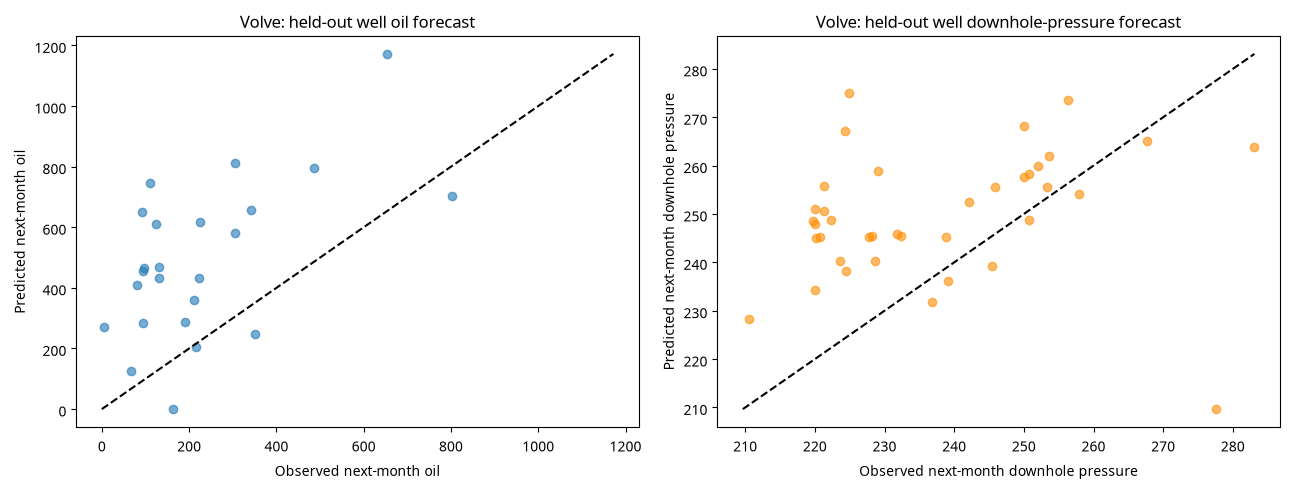

In [8]:
display(oil_group_predictions.sort_values("absolute_error", ascending=False).head(15))
display(pressure_group_predictions.sort_values("absolute_error", ascending=False).head(15))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(oil_group_predictions[oil_target], oil_group_predictions.prediction, alpha=.6)
lo, hi = min(oil_group_predictions[oil_target].min(), oil_group_predictions.prediction.min()), max(oil_group_predictions[oil_target].max(), oil_group_predictions.prediction.max())
axes[0].plot([lo, hi], [lo, hi], "--", color="black")
axes[0].set(title="Volve: held-out well oil forecast", xlabel="Observed next-month oil", ylabel="Predicted next-month oil")
axes[1].scatter(pressure_group_predictions[pressure_target], pressure_group_predictions.prediction, alpha=.6, color="darkorange")
lo, hi = min(pressure_group_predictions[pressure_target].min(), pressure_group_predictions.prediction.min()), max(pressure_group_predictions[pressure_target].max(), pressure_group_predictions.prediction.max())
axes[1].plot([lo, hi], [lo, hi], "--", color="black")
axes[1].set(title="Volve: held-out well downhole-pressure forecast", xlabel="Observed next-month downhole pressure", ylabel="Predicted next-month downhole pressure")
plt.tight_layout(); plt.show()

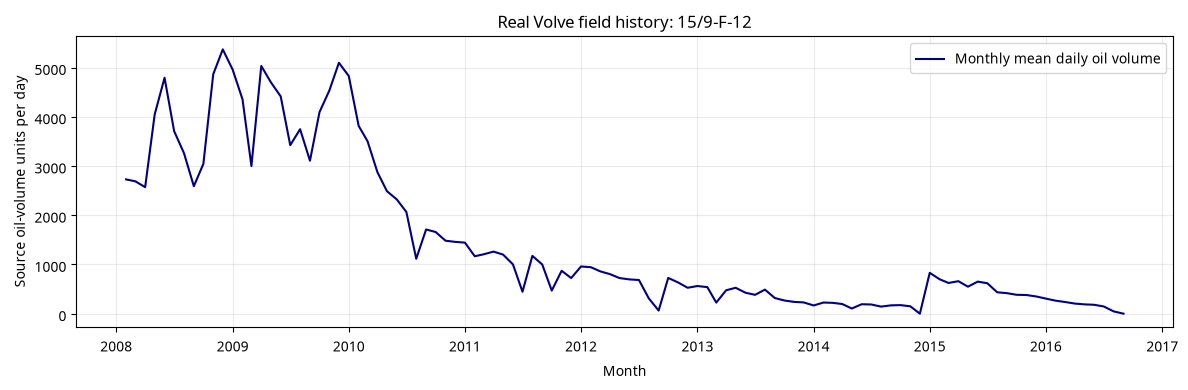

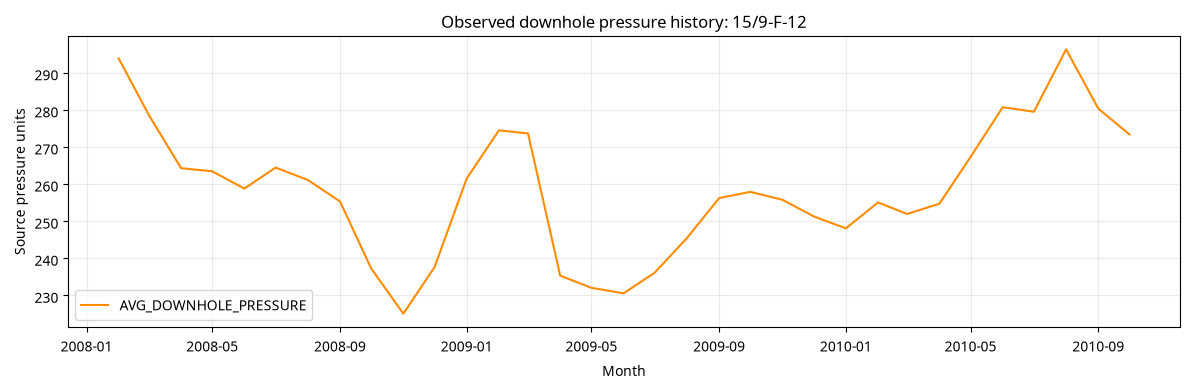

In [9]:
sample_well = "15/9-F-12"
well_history = monthly.loc[monthly.well_id.eq(sample_well)].sort_values("date")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(well_history.date, well_history.oil_rate, label="Monthly mean daily oil volume", color="navy")
ax.set(title=f"Real Volve field history: {sample_well}", xlabel="Month", ylabel="Source oil-volume units per day")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(well_history.date, well_history.bhp, label="AVG_DOWNHOLE_PRESSURE", color="darkorange")
ax.set(title=f"Observed downhole pressure history: {sample_well}", xlabel="Month", ylabel="Source pressure units")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

## 9. Optional Hugging Face foundation-model benchmarks
The repository includes two open-weight Amazon Chronos models: [Chronos-2](https://huggingface.co/amazon/chronos-2) and [Chronos-Bolt-Small](https://huggingface.co/amazon/chronos-bolt-small). Chronos-2 supports multivariate and covariate-aware forecasting; Chronos-Bolt-Small is a smaller univariate forecaster. Both are general time-series models—not petroleum models. The code downloads model weights from Hugging Face the first time they run; expect several hundred megabytes of model files and a working internet connection.

The benchmarks below forecast the same final observed monthly values of 15/9-F-12 from the preceding history. This one-well long-horizon test does not estimate new-well generalization or natural-flow transition accuracy. Median forecasts and 10th–90th percentile intervals are compared with persistence. Negative raw oil forecasts are retained in the raw score and are also shown after a simple nonnegative constraint; clipping is not model calibration.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|                                 | 0/170 [00:00<?, ?it/s]

Loading weights:  26%|██████                 | 45/170 [00:00<00:00, 430.66it/s]

Loading weights:  52%|████████████           | 89/170 [00:00<00:00, 424.45it/s]

Loading weights: 100%|██████████████████████| 170/170 [00:00<00:00, 767.85it/s]

Loading weights:   0%|                                 | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 143/143 [00:00<00:00, 3104.38it/s]

,forecast,MAE,RMSE,R2,negative_raw_fraction,80pct_interval_coverage
0,"Chronos-2 median, raw",507.098145,526.061804,-4.481433,0.904762,0.190476
1,"Chronos-2 median, nonnegative",387.520717,446.674657,-2.951875,0.904762,0.190476
2,Chronos-Bolt-Small median,275.040584,343.652061,-1.339152,0.000000,0.666667
3,Persistence,388.968454,449.203119,-2.996742,0.000000,NaN


,date,oil_rate,chronos2_median,chronos2_q10,chronos2_q90,chronos_bolt_median,chronos_bolt_q10,chronos_bolt_q90
0,2015-01-01,829.437097,21.478516,-82.678833,114.823364,110.233032,-73.000488,309.359497
1,2015-02-01,699.233929,8.923950,-104.590942,104.141724,120.630737,-69.840088,341.764771
2,2015-03-01,623.917097,-0.809937,-133.020996,98.167480,123.260620,-76.171387,369.578003
3,2015-04-01,659.885333,-18.952515,-152.054565,97.355347,133.465942,-77.342041,409.672974
4,2015-05-01,548.273548,-39.835571,-177.381470,100.243042,131.961060,-83.838623,428.540039
5,2015-06-01,651.210000,-44.338989,-202.313232,98.984009,120.638794,-94.005371,442.981445
6,2015-07-01,617.982258,-60.760010,-220.763916,87.092041,115.355957,-101.213135,467.147583
7,2015-08-01,434.621613,-77.533691,-253.010986,89.686646,138.897583,-89.159546,520.976685
8,2015-09-01,416.483667,-91.268555,-270.274292,87.054688,161.090210,-80.336792,586.048462
9,2015-10-01,383.504194,-98.303711,-294.261108,91.671875,157.689331,-84.429810,604.198608


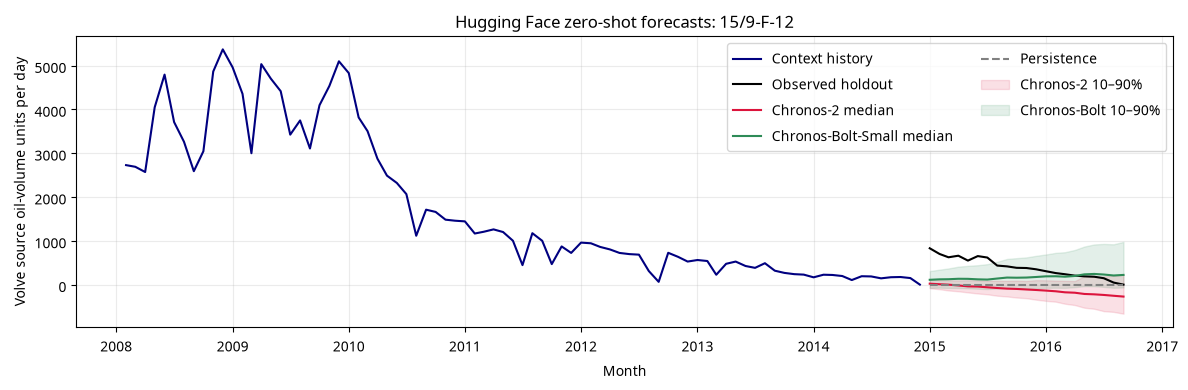

In [10]:
RUN_HUGGING_FACE_MODELS = True
try:
    import chronos
except ImportError:
    RUN_HUGGING_FACE_MODELS = False
    print("Chronos is not installed. Install requirements-models.txt to enable optional model benchmarks.")
if RUN_HUGGING_FACE_MODELS:
    from sgd_ml.huggingface_forecasting import forecast_with_chronos2, forecast_with_chronos_bolt
    series = monthly.loc[monthly.well_id.eq(sample_well), ["date", "oil_rate"]].dropna().sort_values("date")
    split = max(12, int(len(series) * 0.8))
    context = series.iloc[:split]
    observed = series.iloc[split:].reset_index(drop=True)
    horizon = len(observed)
    chronos2_output = forecast_with_chronos2(context.oil_rate.to_numpy(dtype=np.float32), prediction_length=horizon, context_dates=context.date)
    chronos_bolt_output = forecast_with_chronos_bolt(context.oil_rate.to_numpy(dtype=np.float32), prediction_length=horizon)[0]
    chronos2_raw = chronos2_output["predictions"].to_numpy(dtype=float)
    chronos2_clipped = np.clip(chronos2_raw, 0, None)
    chronos2_lower = chronos2_output["0.1"].to_numpy(dtype=float)
    chronos2_upper = chronos2_output["0.9"].to_numpy(dtype=float)
    chronos_bolt_raw = chronos_bolt_output[4].astype(float)
    chronos_bolt_lower = chronos_bolt_output[0].astype(float)
    chronos_bolt_upper = chronos_bolt_output[8].astype(float)
    chronos_scores = pd.DataFrame([
        {"forecast": "Chronos-2 median, raw", **evaluate_regression(observed.oil_rate, chronos2_raw), "negative_raw_fraction": (chronos2_raw < 0).mean(), "80pct_interval_coverage": np.mean((observed.oil_rate >= chronos2_lower) & (observed.oil_rate <= chronos2_upper))},
        {"forecast": "Chronos-2 median, nonnegative", **evaluate_regression(observed.oil_rate, chronos2_clipped), "negative_raw_fraction": (chronos2_raw < 0).mean(), "80pct_interval_coverage": np.mean((observed.oil_rate >= chronos2_lower) & (observed.oil_rate <= chronos2_upper))},
        {"forecast": "Chronos-Bolt-Small median", **evaluate_regression(observed.oil_rate, chronos_bolt_raw), "negative_raw_fraction": (chronos_bolt_raw < 0).mean(), "80pct_interval_coverage": np.mean((observed.oil_rate >= chronos_bolt_lower) & (observed.oil_rate <= chronos_bolt_upper))},
        {"forecast": "Persistence", **evaluate_regression(observed.oil_rate, np.repeat(context.oil_rate.iloc[-1], horizon)), "negative_raw_fraction": 0.0, "80pct_interval_coverage": np.nan},
    ])
    display(chronos_scores)
    hf_predictions = observed.copy()
    hf_predictions["chronos2_median"] = chronos2_raw
    hf_predictions["chronos2_q10"] = chronos2_lower
    hf_predictions["chronos2_q90"] = chronos2_upper
    hf_predictions["chronos_bolt_median"] = chronos_bolt_raw
    hf_predictions["chronos_bolt_q10"] = chronos_bolt_lower
    hf_predictions["chronos_bolt_q90"] = chronos_bolt_upper
    display(hf_predictions.head(12))
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(context.date, context.oil_rate, label="Context history", color="navy")
    ax.plot(observed.date, observed.oil_rate, label="Observed holdout", color="black")
    ax.plot(observed.date, chronos2_raw, label="Chronos-2 median", color="crimson")
    ax.plot(observed.date, chronos_bolt_raw, label="Chronos-Bolt-Small median", color="seagreen")
    ax.plot(observed.date, np.repeat(context.oil_rate.iloc[-1], horizon), label="Persistence", color="gray", linestyle="--")
    ax.fill_between(observed.date, chronos2_lower, chronos2_upper, alpha=.13, color="crimson", label="Chronos-2 10–90%")
    ax.fill_between(observed.date, chronos_bolt_lower, chronos_bolt_upper, alpha=.13, color="seagreen", label="Chronos-Bolt 10–90%")
    ax.set(title=f"Hugging Face zero-shot forecasts: {sample_well}", xlabel="Month", ylabel="Volve source oil-volume units per day")
    ax.grid(alpha=.25); ax.legend(ncol=2); plt.tight_layout(); plt.show()
else:
    print("Hugging Face model inference is optional and disabled because requirements are missing.")

## 10. Arps decline-curve comparison on the identical holdout
The new Arps implementation supports exponential, harmonic, and hyperbolic decline. It fits positive producing-rate observations from the context window only and selects the family by corrected Akaike information criterion (AICc); hyperbolic b is constrained to 0–1, while exponential/harmonic fix b at 0/1. The decline rate `Di` is reported per month. Zero-rate/shut-in months are excluded from Arps fitting, so this baseline does not model downtime, restarts, lift changes, water injection, or economic limits.

This comparison uses the same 15/9-F-12 83-month context and 21-month final holdout as the preceding Chronos comparison. The recursive HistGradientBoosting forecast is trained on one-step oil-rate history features from other Volve wells only, with training labels available by the forecast origin, and then rolled forward recursively without future measurements. Persistence is also scored on those exact 21 target values. This tests a known historical well with a long lead, not natural-flow transition prediction.

Loading weights:   0%|                                 | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 170/170 [00:00<00:00, 6039.26it/s]

Loading weights:   0%|                                 | 0/143 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 143/143 [00:00<00:00, 5624.18it/s]

Selected Arps model: exponential
{'qi': 7712.946607744162, 'Di_per_month': 0.04788972578214892, 'b': 0.0, 'positive_training_months': 82}


,model,MAE,RMSE,R2,negative_prediction_fraction,interval_80_coverage,arps_decline_type,arps_qi,arps_di_per_month,arps_b,arps_training_points,arps_training_aicc
0,Arps Exponential,301.675233,355.719987,-1.506323,0.000000,NaN,exponential,7712.946608,0.04789,0.0,82.0,-132.489886
1,HistGradientBoosting recursive,207.110395,261.545797,-0.354928,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Persistence,388.968454,449.203119,-2.996742,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Chronos-2 raw median,507.098145,526.061804,-4.481433,0.904762,0.190476,NaN,NaN,NaN,NaN,NaN,NaN
4,Chronos-2 nonnegative median,387.520717,446.674657,-2.951875,0.000000,0.190476,NaN,NaN,NaN,NaN,NaN,NaN
5,Chronos-Bolt-Small median,275.040584,343.652061,-1.339152,0.000000,0.666667,NaN,NaN,NaN,NaN,NaN,NaN


,well_id,date,observed_oil_rate,arps_prediction,hgb_recursive_prediction,persistence_prediction,chronos2_raw_prediction,chronos2_nonnegative_prediction,chronos2_q10,chronos2_q90,chronos_bolt_prediction,chronos_bolt_q10,chronos_bolt_q90
0,15/9-F-12,2015-01-01,829.437097,144.937123,328.964926,0.0,21.478516,21.478516,-82.678833,114.823364,110.233032,-73.000488,309.359497
1,15/9-F-12,2015-02-01,699.233929,138.037483,302.367678,0.0,8.923950,8.923950,-104.590942,104.141724,120.630737,-69.840088,341.764771
2,15/9-F-12,2015-03-01,623.917097,132.088301,203.611150,0.0,-0.809937,0.000000,-133.020996,98.167480,123.260620,-76.171387,369.578003
3,15/9-F-12,2015-04-01,659.885333,125.800321,183.010110,0.0,-18.952515,0.000000,-152.054565,97.355347,133.465942,-77.342041,409.672974
4,15/9-F-12,2015-05-01,548.273548,120.000334,293.018181,0.0,-39.835571,0.000000,-177.381470,100.243042,131.961060,-83.838623,428.540039
5,15/9-F-12,2015-06-01,651.210000,114.287794,293.018181,0.0,-44.338989,0.000000,-202.313232,98.984009,120.638794,-94.005371,442.981445
6,15/9-F-12,2015-07-01,617.982258,109.018588,203.371970,0.0,-60.760010,0.000000,-220.763916,87.092041,115.355957,-101.213135,467.147583
7,15/9-F-12,2015-08-01,434.621613,103.828827,188.958596,0.0,-77.533691,0.000000,-253.010986,89.686646,138.897583,-89.159546,520.976685
8,15/9-F-12,2015-09-01,416.483667,98.886121,295.418709,0.0,-91.268555,0.000000,-270.274292,87.054688,161.090210,-80.336792,586.048462
9,15/9-F-12,2015-10-01,383.504194,94.327005,343.615296,0.0,-98.303711,0.000000,-294.261108,91.671875,157.689331,-84.429810,604.198608


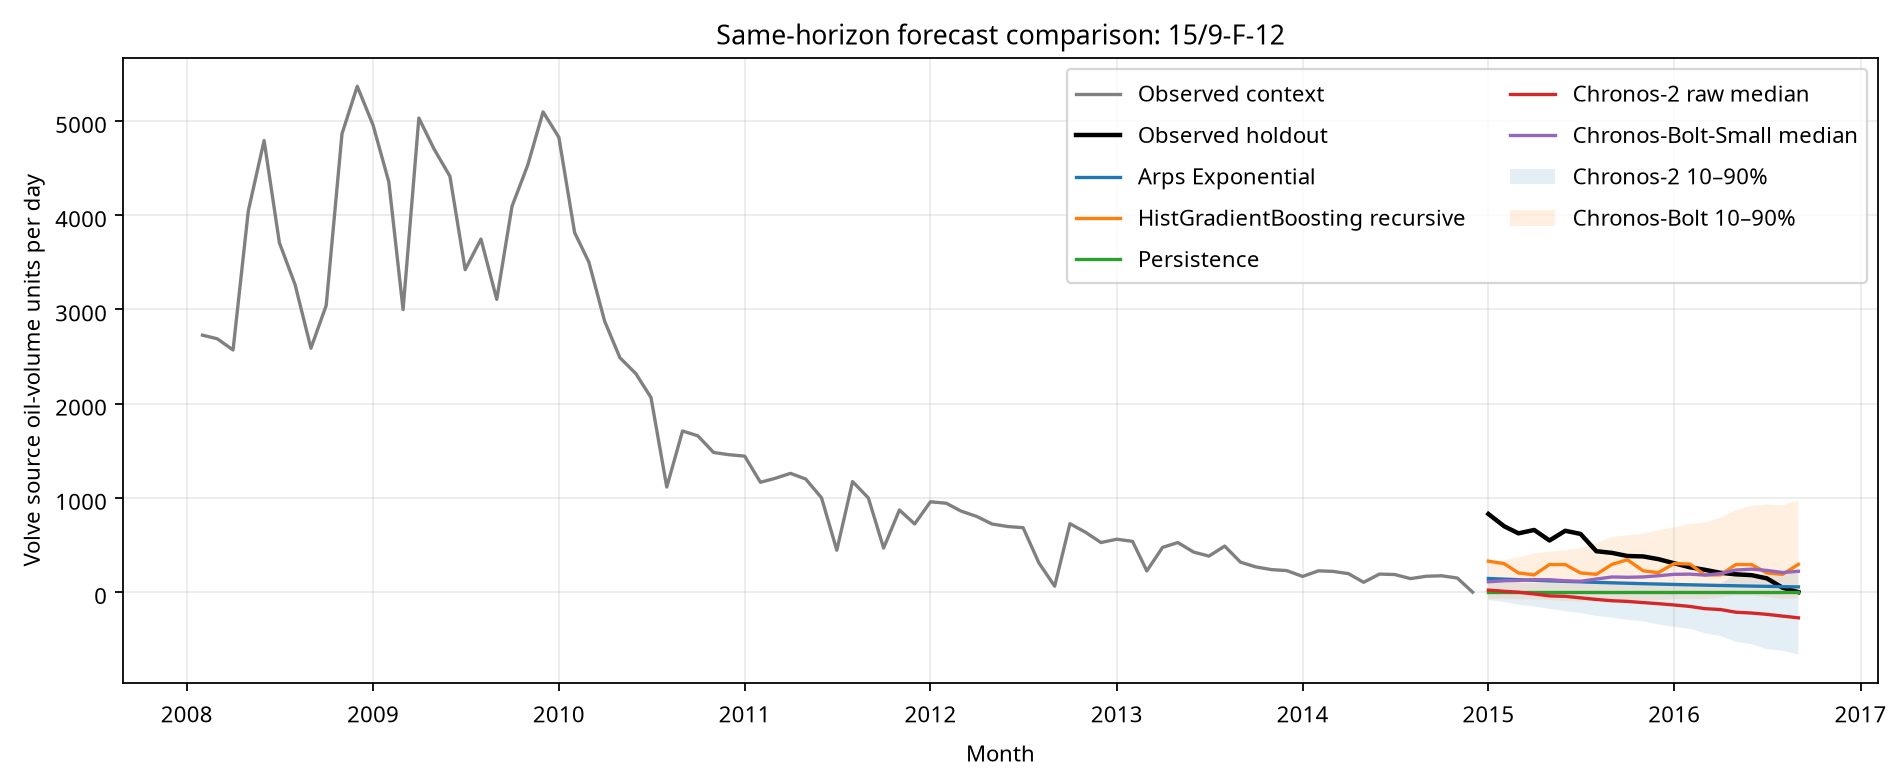

In [11]:
from sgd_ml.arps_comparison import run_arps_comparison
from IPython.display import Image, display
arps_comparison = run_arps_comparison(
    workbook_path=SOURCE_PATH,
    forecast_well=sample_well,
    train_fraction=0.8,
    include_huggingface=RUN_HUGGING_FACE_MODELS,
    output_dir=ROOT / "reports/arps_comparison",
)
print("Selected Arps model:", arps_comparison["arps_fit"].decline_type)
print({"qi": arps_comparison["arps_fit"].qi, "Di_per_month": arps_comparison["arps_fit"].di, "b": arps_comparison["arps_fit"].b, "positive_training_months": arps_comparison["arps_fit"].observations_used})
display(arps_comparison["metrics"])
display(arps_comparison["predictions"].head(12))
display(Image(filename=str(ROOT / "reports/arps_comparison/arps_model_comparison.png")))

## 11. Synthetic data role and restrictions
The existing synthetic file is retained in the project for software/pipeline checks. It is not a reservoir simulator, not calibrated to Volve, and not field evidence. It does not provide valid additional natural-flow transition labels for the Volve wells. Mixing its generated patterns into Volve training could reduce field accuracy and create misleading confidence. The notebook therefore trains and evaluates the field model on field data only. Synthetic scenarios should be integrated only after calibration to solution-gas-drive PVT, material balance, relative permeability, and known field ranges, and then assessed by an explicit real-field ablation.

## 12. Conclusions and next data requirement
This notebook establishes a real-field baseline for oil-rate and downhole-pressure forecasting with limited Volve records. It does not satisfy the project’s central natural-flow inadequacy target because it lacks documented per-well lift state, transition dates, solution-gas-drive classification, and event/censoring definitions. The team must source solution-gas-drive wells with natural-flow periods and verified transition or economic-limit records before claiming field performance for that target. The best way to test whether synthetic data helps is to compare field-only versus field-plus-calibrated-simulation training on entirely held-out real solution-gas-drive wells.